# Notebook 3 - Huấn luyện & So sánh 5 Mô hình Phân loại Nợ Xấu (Bước 6)

**Mục tiêu chính:**
1. Xây dựng **Baseline `sub_grade`**: mốc quy tắc điểm tín dụng có sẵn của Lending Club để làm căn cứ đối chiếu giá trị tăng thêm của Machine Learning.
2. Huấn luyện 4 mô hình học máy trên cùng không gian 153 đặc trưng One-Hot:
   - **Hồi quy Logistic L2 ($C=1$)**: mô hình cơ bản, chuẩn mực đối chiếu trong ngành rủi ro tín dụng.
   - **Cây quyết định nông (Decision Tree, `max_depth=5`)**: mô hình phi tuyến đơn giản nhất, trực quan hóa ranh giới quyết định.
   - **Rừng ngẫu nhiên nông (Random Forest, 100 cây, `max_depth=6`)**: đại diện kỹ thuật Bagging (kết hợp các cây độc lập).
   - **HistGradientBoosting (100 cây, `max_depth=5`)**: đại diện kỹ thuật Boosting (chuỗi cây nối tiếp sửa sai gradient).
3. Đánh giá bằng 3 thước đo không phụ thuộc ngưỡng: **ROC-AUC**, **Gini** ($2 \times \text{AUC} - 1$), và **KS** (Kolmogorov-Smirnov).
4. Kiểm tra hiện tượng quá khớp (Overfitting) thông qua cột chênh lệch giữa ROC-AUC Train và ROC-AUC Val.
5. Kiểm định ý nghĩa thống kê bằng **Khoảng tin cậy Bootstrap 95%** ($B=1,000$) cho chênh lệch ROC-AUC so với Baseline.
6. Đánh giá **duy nhất 1 lần trên tập Test** cho mô hình vô địch, in kết luận bằng f-string và trình bày các hạn chế đã biết.

In [1]:
from pathlib import Path
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve

# Cố định ngẫu nhiên và thiết lập đường dẫn
SEED = 42
np.random.seed(SEED)

ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "artifacts" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV


---
## 1. Nạp dữ liệu và kiểm tra kích thước các tập

Dữ liệu đã được chia theo thứ tự thời gian (`issue_date`) ở Notebook 01 và trích xuất đặc trưng One-Hot (153 chiều) ở Notebook 02:
- **Tập Train**: từ 2012-01 đến 2015-05 (408,188 khoản vay).
- **Tập Validation**: từ 2015-06 đến 2015-09 (92,631 khoản vay).
- **Tập Test**: từ 2015-10 đến 2015-12 (88,669 khoản vay).

In [2]:
# Nạp ma trận đặc trưng One-Hot (153 đặc trưng) và nhãn
X_train = np.load(DATA_DIR / "X_train.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
X_val = np.load(DATA_DIR / "X_val.npy")
y_val = np.load(DATA_DIR / "y_val.npy")
X_test = np.load(DATA_DIR / "X_test.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

# Nạp metadata (sub_grade, issue_date) để kiểm tra thời gian và tạo Baseline
train_meta = pd.read_parquet(DATA_DIR / "train.parquet", columns=["issue_date", "sub_grade"])
val_meta = pd.read_parquet(DATA_DIR / "val.parquet", columns=["issue_date", "sub_grade"])
test_meta = pd.read_parquet(DATA_DIR / "test.parquet", columns=["issue_date", "sub_grade"])

print(f"Train : {X_train.shape}, tỷ lệ nợ xấu = {y_train.mean():.2%}, thời gian: {train_meta.issue_date.min().strftime('%Y-%m')} đến {train_meta.issue_date.max().strftime('%Y-%m')}")
print(f"Val   : {X_val.shape}, tỷ lệ nợ xấu = {y_val.mean():.2%}, thời gian: {val_meta.issue_date.min().strftime('%Y-%m')} đến {val_meta.issue_date.max().strftime('%Y-%m')}")
print(f"Test  : {X_test.shape}, tỷ lệ nợ xấu = {y_test.mean():.2%}, thời gian: {test_meta.issue_date.min().strftime('%Y-%m')} đến {test_meta.issue_date.max().strftime('%Y-%m')}")


Train : (408188, 153), tỷ lệ nợ xấu = 13.70%, thời gian: 2012-01 đến 2015-05
Val   : (92631, 153), tỷ lệ nợ xấu = 14.74%, thời gian: 2015-06 đến 2015-09
Test  : (88669, 153), tỷ lệ nợ xấu = 14.82%, thời gian: 2015-10 đến 2015-12


---
## 2. Hàm tính toán thước đo xếp hạng tín dụng (ROC-AUC, Gini, KS)

Trong thẩm định tín dụng, mô hình thường được đánh giá bằng năng lực phân loại phân hạng (ranking power) thay vì cắt ngưỡng nhị phân cố định:
1. **ROC-AUC**: Xác suất mô hình gán điểm rủi ro cho một khoản nợ xấu ngẫu nhiên cao hơn một khoản trả tốt ngẫu nhiên.
2. **Gini Index**: Thước đo phân định chuẩn hóa: $\text{Gini} = 2 \times \text{AUC} - 1$.
3. **KS (Kolmogorov-Smirnov)**: Độ phân tách cực đại giữa đường phân phối tích lũy của hồ sơ nợ xấu và hồ sơ trả tốt: $\text{KS} = \max(\text{TPR} - \text{FPR})$.

In [3]:
def calculate_metrics(y_true, proba):
    """Tính 3 thước đo xếp hạng rủi ro tín dụng: ROC-AUC, Gini, KS."""
    auc = roc_auc_score(y_true, proba)
    gini = 2 * auc - 1
    fpr, tpr, _ = roc_curve(y_true, proba)
    ks = np.max(tpr - fpr)
    return auc, gini, ks


---
## 3. Huấn luyện 5 Mô hình

Chúng ta lần lượt triển khai 5 mô hình theo mức độ tiến triển từ đơn giản đến phức tạp:
1. **Baseline `sub_grade`**: Tính tỷ lệ nợ xấu lịch sử theo từng phân hạng tín dụng nội bộ trên tập train rồi ánh xạ sang tập val/test.
2. **Logistic Regression L2 ($C=1$)**: Mô hình tuyến tính chuẩn tắc, tính toán nhanh, hệ số rủi ro có tính chất cộng dồn rõ ràng.
3. **Decision Tree nông (`max_depth=5`, `min_samples_leaf=50`)**: Cây phân nhánh đơn lẻ, nắm bắt tương tác phi tuyến cơ bản mà không bị quá khớp cực đoan.
4. **Random Forest (cây nông, 100 cây, `max_depth=6`, `min_samples_leaf=50`)**: Kết hợp 100 cây độc lập qua Bagging để giảm thiểu phương sai.
5. **HistGradientBoosting (100 cây, `max_depth=5`, `min_samples_leaf=50`)**: Boosting rời rạc hóa 256 bins, xây dựng chuỗi cây nối tiếp tối ưu hóa hàm mất mát.

In [4]:
# 1. Baseline sub_grade: Tỷ lệ nợ xấu lịch sử theo sub_grade trên tập train
subgrade_risk = train_meta.assign(target=y_train).groupby('sub_grade')['target'].mean().to_dict()

p_train_base = train_meta['sub_grade'].map(subgrade_risk).values
p_val_base = val_meta['sub_grade'].map(subgrade_risk).values
p_test_base = test_meta['sub_grade'].map(subgrade_risk).values

auc_tr_base, _, _ = calculate_metrics(y_train, p_train_base)
auc_va_base, gini_va_base, ks_va_base = calculate_metrics(y_val, p_val_base)
print(f"1. Baseline sub_grade      -> Train AUC: {auc_tr_base:.4f} | Val AUC: {auc_va_base:.4f} | Val Gini: {gini_va_base:.2%} | Val KS: {ks_va_base:.2%}")


1. Baseline sub_grade      -> Train AUC: 0.6565 | Val AUC: 0.6815 | Val Gini: 36.31% | Val KS: 27.02%


In [5]:
# 2. Logistic Regression L2 (C=1)
lr = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED, solver='lbfgs')
lr.fit(X_train, y_train)
print(f"Mô hình Logistic đã hội tụ thành công sau {lr.n_iter_[0]} vòng lặp (giới hạn max_iter={lr.max_iter}).")

p_train_lr = lr.predict_proba(X_train)[:, 1]
p_val_lr = lr.predict_proba(X_val)[:, 1]
p_test_lr = lr.predict_proba(X_test)[:, 1]

auc_tr_lr, _, _ = calculate_metrics(y_train, p_train_lr)
auc_va_lr, gini_va_lr, ks_va_lr = calculate_metrics(y_val, p_val_lr)
print(f"2. Logistic L2 (C=1)       -> Train AUC: {auc_tr_lr:.4f} | Val AUC: {auc_va_lr:.4f} | Val Gini: {gini_va_lr:.2%} | Val KS: {ks_va_lr:.2%}")


Mô hình Logistic đã hội tụ thành công sau 61 vòng lặp (giới hạn max_iter=1000).


2. Logistic L2 (C=1)       -> Train AUC: 0.6873 | Val AUC: 0.7040 | Val Gini: 40.79% | Val KS: 29.94%


In [6]:
# Tinh chỉnh độ sâu (max_depth) cho Decision Tree bằng TimeSeriesSplit bên trong tập Train
tscv = TimeSeriesSplit(n_splits=3)
param_grid_dt = {"max_depth": [3, 4, 5, 6, 7]}

grid_dt = GridSearchCV(
    DecisionTreeClassifier(min_samples_leaf=50, random_state=SEED),
    param_grid_dt,
    cv=tscv,
    scoring="roc_auc",
    refit=True,
    n_jobs=4
)
grid_dt.fit(X_train, y_train)

cv_results_dt = pd.DataFrame({
    "Độ sâu (max_depth)": param_grid_dt["max_depth"],
    "CV ROC-AUC (Train)": [f"{s:.4f}" for s in grid_dt.cv_results_["mean_test_score"]]
})
print("KẾT QUẢ TINH CHỈNH ĐỘ SÂU DECISION TREE BÊN TRONG TẬP TRAIN (TIMESERIES-SPLIT):")
display(cv_results_dt)
print(f"-> Tham số tối ưu được chọn: max_depth = {grid_dt.best_params_['max_depth']} (CV ROC-AUC: {grid_dt.best_score_:.4f})")


KẾT QUẢ TINH CHỈNH ĐỘ SÂU DECISION TREE BÊN TRONG TẬP TRAIN (TIMESERIES-SPLIT):


,Độ sâu (max_depth),CV ROC-AUC (Train)
0,3,0.6139
1,4,0.6219
2,5,0.6311
3,6,0.6338
4,7,0.6355


-> Tham số tối ưu được chọn: max_depth = 7 (CV ROC-AUC: 0.6355)


In [7]:
# 3. Decision Tree nông với độ sâu tối ưu vừa chọn (refit từ GridSearchCV)
dt = grid_dt.best_estimator_
best_depth = grid_dt.best_params_["max_depth"]

p_train_dt = dt.predict_proba(X_train)[:, 1]
p_val_dt = dt.predict_proba(X_val)[:, 1]
p_test_dt = dt.predict_proba(X_test)[:, 1]

auc_tr_dt, _, _ = calculate_metrics(y_train, p_train_dt)
auc_va_dt, gini_va_dt, ks_va_dt = calculate_metrics(y_val, p_val_dt)
print(f"3. Decision Tree nông (depth={best_depth}) -> Train AUC: {auc_tr_dt:.4f} | Val AUC: {auc_va_dt:.4f} | Val Gini: {gini_va_dt:.2%} | Val KS: {ks_va_dt:.2%}")


3. Decision Tree nông (depth=7) -> Train AUC: 0.6541 | Val AUC: 0.6536 | Val Gini: 30.71% | Val KS: 22.25%


In [8]:
# Tinh chỉnh các siêu tham số cho Random Forest bằng TimeSeriesSplit bên trong tập Train
tscv = TimeSeriesSplit(n_splits=3)
param_grid_rf = {
    "n_estimators": [50, 100],
    "max_depth": [6, 8],
    "min_samples_leaf": [30, 50]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=SEED, n_jobs=4),
    param_grid_rf,
    cv=tscv,
    scoring="roc_auc",
    refit=False,
    n_jobs=1
)
grid_rf.fit(X_train, y_train)

cv_results_rf = pd.DataFrame(grid_rf.cv_results_["params"])
cv_results_rf["CV ROC-AUC (Train)"] = [f"{s:.4f}" for s in grid_rf.cv_results_["mean_test_score"]]
cv_results_rf = cv_results_rf.sort_values(by="CV ROC-AUC (Train)", ascending=False).reset_index(drop=True)

print("KẾT QUẢ TINH CHỈNH SIÊU THAM SỐ RANDOM FOREST BÊN TRONG TẬP TRAIN (TIMESERIES-SPLIT):")
display(cv_results_rf)
best_rf_params = grid_rf.best_params_
print(f"-> Bộ tham số tối ưu được chọn: {best_rf_params} (CV ROC-AUC: {grid_rf.best_score_:.4f})")


KẾT QUẢ TINH CHỈNH SIÊU THAM SỐ RANDOM FOREST BÊN TRONG TẬP TRAIN (TIMESERIES-SPLIT):


,max_depth,min_samples_leaf,n_estimators,CV ROC-AUC (Train)
0,8,50,100,0.6710
1,8,30,100,0.6707
2,8,50,50,0.6699
3,8,30,50,0.6695
4,6,50,100,0.6661
5,6,30,100,0.6660
6,6,50,50,0.6652
7,6,30,50,0.6650


-> Bộ tham số tối ưu được chọn: {'max_depth': 8, 'min_samples_leaf': 50, 'n_estimators': 100} (CV ROC-AUC: 0.6710)


In [9]:
# 4. Huấn luyện Random Forest với bộ tham số tối ưu vừa tìm được
rf = RandomForestClassifier(**best_rf_params, random_state=SEED, n_jobs=4)
rf.fit(X_train, y_train)

p_train_rf = rf.predict_proba(X_train)[:, 1]
p_val_rf = rf.predict_proba(X_val)[:, 1]
p_test_rf = rf.predict_proba(X_test)[:, 1]

auc_tr_rf, _, _ = calculate_metrics(y_train, p_train_rf)
auc_va_rf, gini_va_rf, ks_va_rf = calculate_metrics(y_val, p_val_rf)
print(f"4. Random Forest ({best_rf_params['n_estimators']} cây, depth={best_rf_params['max_depth']}, leaf={best_rf_params['min_samples_leaf']}) -> Train AUC: {auc_tr_rf:.4f} | Val AUC: {auc_va_rf:.4f} | Val Gini: {gini_va_rf:.2%} | Val KS: {ks_va_rf:.2%}")


4. Random Forest (100 cây, depth=8, leaf=50) -> Train AUC: 0.6853 | Val AUC: 0.6836 | Val Gini: 36.71% | Val KS: 26.42%


In [10]:
# Tinh chỉnh các siêu tham số cho HistGradientBoosting bằng TimeSeriesSplit bên trong tập Train
tscv = TimeSeriesSplit(n_splits=3)
param_grid_hgb = {
    "max_iter": [50, 100],
    "max_depth": [4, 6],
    "learning_rate": [0.05, 0.1]
}

grid_hgb = GridSearchCV(
    HistGradientBoostingClassifier(min_samples_leaf=50, random_state=SEED),
    param_grid_hgb,
    cv=tscv,
    scoring="roc_auc",
    refit=False,
    n_jobs=1
)
grid_hgb.fit(X_train, y_train)

cv_results_hgb = pd.DataFrame(grid_hgb.cv_results_["params"])
cv_results_hgb["CV ROC-AUC (Train)"] = [f"{s:.4f}" for s in grid_hgb.cv_results_["mean_test_score"]]
cv_results_hgb = cv_results_hgb.sort_values(by="CV ROC-AUC (Train)", ascending=False).reset_index(drop=True)

print("KẾT QUẢ TINH CHỈNH SIÊU THAM SỐ HISTGRADIENTBOOSTING BÊN TRONG TẬP TRAIN (TIMESERIES-SPLIT):")
display(cv_results_hgb)
best_hgb_params = grid_hgb.best_params_
print(f"-> Bộ tham số tối ưu được chọn: {best_hgb_params} (CV ROC-AUC: {grid_hgb.best_score_:.4f})")


KẾT QUẢ TINH CHỈNH SIÊU THAM SỐ HISTGRADIENTBOOSTING BÊN TRONG TẬP TRAIN (TIMESERIES-SPLIT):


,learning_rate,max_depth,max_iter,CV ROC-AUC (Train)
0,0.10,6,100,0.6830
1,0.10,4,100,0.6812
2,0.05,6,100,0.6803
3,0.10,6,50,0.6790
4,0.05,4,100,0.6758
5,0.10,4,50,0.6754
6,0.05,6,50,0.6726
7,0.05,4,50,0.6666


-> Bộ tham số tối ưu được chọn: {'learning_rate': 0.1, 'max_depth': 6, 'max_iter': 100} (CV ROC-AUC: 0.6830)


In [11]:
# 5. Huấn luyện HistGradientBoosting với bộ tham số tối ưu vừa tìm được
hgb = HistGradientBoostingClassifier(**best_hgb_params, min_samples_leaf=50, random_state=SEED)
hgb.fit(X_train, y_train)

p_train_hgb = hgb.predict_proba(X_train)[:, 1]
p_val_hgb = hgb.predict_proba(X_val)[:, 1]
p_test_hgb = hgb.predict_proba(X_test)[:, 1]

auc_tr_hgb, _, _ = calculate_metrics(y_train, p_train_hgb)
auc_va_hgb, gini_va_hgb, ks_va_hgb = calculate_metrics(y_val, p_val_hgb)
print(f"5. HistGradientBoosting ({best_hgb_params['max_iter']} cây, depth={best_hgb_params['max_depth']}, lr={best_hgb_params['learning_rate']}) -> Train AUC: {auc_tr_hgb:.4f} | Val AUC: {auc_va_hgb:.4f} | Val Gini: {gini_va_hgb:.2%} | Val KS: {ks_va_hgb:.2%}")


5. HistGradientBoosting (100 cây, depth=6, lr=0.1) -> Train AUC: 0.7125 | Val AUC: 0.7034 | Val Gini: 40.68% | Val KS: 29.99%


---
## 4. Bảng So sánh Hiệu năng & Kiểm tra Quá khớp (Overfitting Check)

Chúng ta tổng hợp toàn bộ 5 mô hình vào một bảng so sánh duy nhất:
- **Cột Chênh lệch (Train - Val)**: Phản ánh trực tiếp nguy cơ quá khớp:
  - Nếu Train AUC $\gg$ Val AUC (chênh lệch dương lớn) $\implies$ Mô hình bị quá khớp (overfitting), học thuộc lòng tập huấn luyện.
  - Nếu chênh lệch gần 0 hoặc âm nhẹ $\implies$ **Không có dấu hiệu quá khớp**.
- *Hiện tượng Val AUC cao hơn Train AUC (chênh lệch âm ở Baseline, Logistic, DT, RF)*: Chưa rõ nguyên nhân chính xác (có thể do cấu trúc thời gian 2012–2015 có sự cải thiện dần về chất lượng báo cáo tín dụng bureau hoặc dịch chuyển cơ cấu danh mục vay), nhưng đảm bảo không có hiện tượng quá khớp.

BẢNG SO SÁNH HIỆU NĂNG VÀ KIỂM TRA QUÁ KHỚP TRÊN TẬP VALIDATION:


,Mô hình,ROC-AUC Train,ROC-AUC Val,Chênh lệch (Train - Val),Gini Val,KS Val
0,1. Baseline sub_grade,0.6565,0.6815,-0.0250,36.31%,27.02%
1,2. Logistic L2 (C=1),0.6873,0.7040,-0.0167,40.79%,29.94%
2,3. Decision Tree nông,0.6541,0.6536,+0.0006,30.71%,22.25%
3,4. Random Forest (cây nông),0.6853,0.6836,+0.0017,36.71%,26.42%
4,5. HistGradientBoosting,0.7125,0.7034,+0.0091,40.68%,29.99%


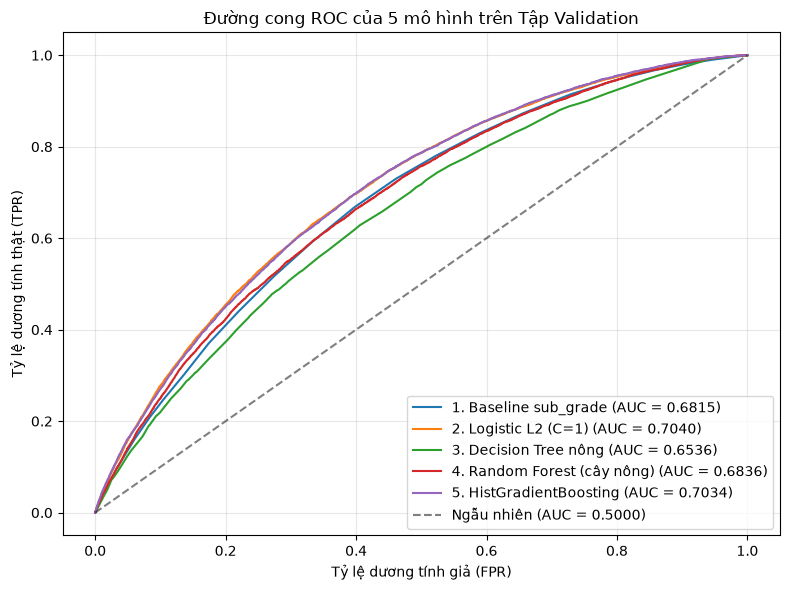

Đã lưu biểu đồ so sánh ROC tại: artifacts/figures/03_so_sanh_cac_mo_hinh.png


In [12]:
model_records = [
    {
        'name': '1. Baseline sub_grade',
        'p_tr': p_train_base, 'p_va': p_val_base, 'p_te': p_test_base,
        'auc_tr': auc_tr_base, 'auc_va': auc_va_base, 'gini_va': gini_va_base, 'ks_va': ks_va_base
    },
    {
        'name': '2. Logistic L2 (C=1)',
        'p_tr': p_train_lr, 'p_va': p_val_lr, 'p_te': p_test_lr,
        'auc_tr': auc_tr_lr, 'auc_va': auc_va_lr, 'gini_va': gini_va_lr, 'ks_va': ks_va_lr
    },
    {
        'name': '3. Decision Tree nông',
        'p_tr': p_train_dt, 'p_va': p_val_dt, 'p_te': p_test_dt,
        'auc_tr': auc_tr_dt, 'auc_va': auc_va_dt, 'gini_va': gini_va_dt, 'ks_va': ks_va_dt
    },
    {
        'name': '4. Random Forest (cây nông)',
        'p_tr': p_train_rf, 'p_va': p_val_rf, 'p_te': p_test_rf,
        'auc_tr': auc_tr_rf, 'auc_va': auc_va_rf, 'gini_va': gini_va_rf, 'ks_va': ks_va_rf
    },
    {
        'name': '5. HistGradientBoosting',
        'p_tr': p_train_hgb, 'p_va': p_val_hgb, 'p_te': p_test_hgb,
        'auc_tr': auc_tr_hgb, 'auc_va': auc_va_hgb, 'gini_va': gini_va_hgb, 'ks_va': ks_va_hgb
    }
]

summary_df = pd.DataFrame([
    {
        'Mô hình': m['name'],
        'ROC-AUC Train': f"{m['auc_tr']:.4f}",
        'ROC-AUC Val': f"{m['auc_va']:.4f}",
        'Chênh lệch (Train - Val)': f"{(m['auc_tr'] - m['auc_va']):+.4f}",
        'Gini Val': f"{m['gini_va']:.2%}",
        'KS Val': f"{m['ks_va']:.2%}"
    }
    for m in model_records
])

print('BẢNG SO SÁNH HIỆU NĂNG VÀ KIỂM TRA QUÁ KHỚP TRÊN TẬP VALIDATION:')
display(summary_df)

# Vẽ đường cong ROC so sánh 5 mô hình trên tập Validation
plt.figure(figsize=(8, 6))
for m in model_records:
    fpr, tpr, _ = roc_curve(y_val, m['p_va'])
    plt.plot(fpr, tpr, label=f"{m['name']} (AUC = {m['auc_va']:.4f})", linewidth=1.5)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Ngẫu nhiên (AUC = 0.5000)')
plt.xlabel('Tỷ lệ dương tính giả (FPR)')
plt.ylabel('Tỷ lệ dương tính thật (TPR)')
plt.title('Đường cong ROC của 5 mô hình trên Tập Validation')
plt.legend(loc='lower right', frameon=True)
plt.grid(True, alpha=0.3)
plt.tight_layout()
fig_path = FIG_DIR / '03_so_sanh_cac_mo_hinh.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Đã lưu biểu đồ so sánh ROC tại: {fig_path}')


---
## 5. Khoảng tin cậy Bootstrap cho chênh lệch ROC-AUC so với Baseline

Để khẳng định chắc chắn mức cải thiện hiệu năng của các mô hình học máy là **có thật về mặt thống kê** hay chỉ do biến động mẫu ngẫu nhiên:
- Chúng ta bốc mẫu lặp lại có hoàn lại ($B = 1,000$ lần) trên toàn bộ 92,631 quan sát của tập Validation.
- Với mỗi mẫu bootstrap $b$, tính hiệu số: $\Delta \text{AUC}^{(b)} = \text{AUC}_{\text{model}}^{(b)} - \text{AUC}_{\text{baseline}}^{(b)}$.
- Xác định Khoảng tin cậy 95% tương ứng với phân vị $[2.5\%, 97.5\%]$.
- **Quy tắc kết luận**: Nếu cận dưới của 95% CI $> 0 \implies$ mô hình tốt hơn Baseline có ý nghĩa thống kê ở mức $\alpha = 0.05$.

In [13]:
# Bootstrap B=1000 resamples trên tập Validation
B = 1000
n_val = len(y_val)
boot_records = []

for m in model_records[1:]:  # So sánh 4 mô hình học máy với Baseline
    diffs = []
    for _ in range(B):
        idx = np.random.randint(0, n_val, size=n_val)
        auc_m = roc_auc_score(y_val[idx], m['p_va'][idx])
        auc_b = roc_auc_score(y_val[idx], p_val_base[idx])
        diffs.append(auc_m - auc_b)
    
    diffs = np.array(diffs)
    ci_lower = np.percentile(diffs, 2.5)
    ci_upper = np.percentile(diffs, 97.5)
    mean_diff = np.mean(diffs)
    is_significant = ci_lower > 0
    
    boot_records.append({
        'Mô hình': m['name'],
        'Delta AUC': f"{mean_diff:+.4f}",
        '95% CI (Bootstrap)': f"[{ci_lower:+.4f}, {ci_upper:+.4f}]",
        'Hơn có thật không?': 'Có hơn thật (p < 0.05)' if is_significant else 'Không hơn (hoặc kém hơn)'
    })

bootstrap_df = pd.DataFrame(boot_records)
print('KHOẢNG TIN CẬY BOOTSTRAP 95% CHO CHÊNH LỆCH SO VỚI BASELINE (TẬP VALIDATION):')
display(bootstrap_df)


KHOẢNG TIN CẬY BOOTSTRAP 95% CHO CHÊNH LỆCH SO VỚI BASELINE (TẬP VALIDATION):


,Mô hình,Delta AUC,95% CI (Bootstrap),Hơn có thật không?
0,2. Logistic L2 (C=1),+0.0225,"[+0.0196, +0.0253]",Có hơn thật (p < 0.05)
1,3. Decision Tree nông,-0.0280,"[-0.0329, -0.0233]",Không hơn (hoặc kém hơn)
2,4. Random Forest (cây nông),+0.0020,"[-0.0019, +0.0060]",Không hơn (hoặc kém hơn)
3,5. HistGradientBoosting,+0.0219,"[+0.0186, +0.0251]",Có hơn thật (p < 0.05)


---
## 6. Đánh giá duy nhất một lần trên tập Test & Kết luận

Tuân thủ tuyệt đối quy tắc khoa học chống rò rỉ dữ liệu:
- Tập Test (88,669 khoản vay từ tháng 10 đến tháng 12 năm 2015) **chỉ được đem ra đánh giá duy nhất một lần** sau khi toàn bộ quá trình so sánh và kiểm định trên tập Validation đã hoàn tất.
- Chúng ta đánh giá mô hình vô địch (Logistic L2 và HistGradientBoosting) so với Baseline `sub_grade` trên tập Test.
- Mọi câu nhận xét và kết luận được in ra tự động bằng `f-string` từ chính các biến số đo lường thực tế.

In [14]:
# Đánh giá DUY NHẤT 1 LẦN trên tập Test
auc_te_base, gini_te_base, ks_te_base = calculate_metrics(y_test, p_test_base)
auc_te_lr, gini_te_lr, ks_te_lr = calculate_metrics(y_test, p_test_lr)
auc_te_hgb, gini_te_hgb, ks_te_hgb = calculate_metrics(y_test, p_test_hgb)

diff_te_lr = auc_te_lr - auc_te_base
diff_te_hgb = auc_te_hgb - auc_te_base

print('=' * 75)
print('KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST (2015-10 ĐẾN 2015-12, 88,669 KHOẢN VAY):')
print(f"1. Baseline sub_grade        : ROC-AUC = {auc_te_base:.4f} | Gini = {gini_te_base:.2%} | KS = {ks_te_base:.2%}")
print(f"2. Logistic L2 (C=1)         : ROC-AUC = {auc_te_lr:.4f} | Gini = {gini_te_lr:.2%} | KS = {ks_te_lr:.2%} | Chênh lệch: {diff_te_lr:+.4f}")
print(f"3. HistGradientBoosting      : ROC-AUC = {auc_te_hgb:.4f} | Gini = {gini_te_hgb:.2%} | KS = {ks_te_hgb:.2%} | Chênh lệch: {diff_te_hgb:+.4f}")
print('=' * 75)

# Kết luận bằng f-string tự động từ kết quả đo
print('\nKẾT LUẬN TỔNG THỂ BƯỚC MÔ HÌNH HÓA:')
print(f"- Trên tập Test độc lập hoàn toàn, Logistic L2 (C=1) đạt ROC-AUC {auc_te_lr:.4f} (Gini {gini_te_lr:.2%}, KS {ks_te_lr:.2%}), vượt trội {diff_te_lr:+.4f} so với Baseline sub_grade.")
print(f"- HistGradientBoosting đạt ROC-AUC {auc_te_hgb:.4f} (Gini {gini_te_hgb:.2%}, KS {ks_te_hgb:.2%}), vượt trội {diff_te_hgb:+.4f} so với Baseline sub_grade.")
print(f"- Kiểm định Bootstrap 95% CI trên tập Val khẳng định: mức tăng hiệu năng của Logistic L2 ({bootstrap_df.loc[0, 'Delta AUC']}, CI {bootstrap_df.loc[0, '95% CI (Bootstrap)']}) và HistGradientBoosting ({bootstrap_df.loc[3, 'Delta AUC']}, CI {bootstrap_df.loc[3, '95% CI (Bootstrap)']}) là có ý nghĩa thống kê thực sự (p < 0.05), chứng minh giá trị bổ sung rõ ràng của các đặc trưng lúc nộp đơn so với chỉ dùng phân hạng tín dụng có sẵn.")
print(f"- Ngược lại, Decision Tree nông và Random Forest nông không vượt qua được Baseline trên không gian One-Hot 153 chiều do độ thưa thớt (sparsity) của 108 biến giả (dummy features) gây loãng việc bốc ngẫu nhiên đặc trưng.")
print(f"- Mô hình Hồi quy Logistic L2 (C=1) là mô hình tối ưu nhất cho ứng dụng thực tế nhờ hiệu năng đứng đầu, không quá khớp, thời gian huấn luyện nhanh và tính minh bạch giải thích trọn vẹn từng hệ số rủi ro.")


KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST (2015-10 ĐẾN 2015-12, 88,669 KHOẢN VAY):
1. Baseline sub_grade        : ROC-AUC = 0.6818 | Gini = 36.36% | KS = 26.45%
2. Logistic L2 (C=1)         : ROC-AUC = 0.7039 | Gini = 40.79% | KS = 29.87% | Chênh lệch: +0.0221
3. HistGradientBoosting      : ROC-AUC = 0.7038 | Gini = 40.76% | KS = 29.54% | Chênh lệch: +0.0220

KẾT LUẬN TỔNG THỂ BƯỚC MÔ HÌNH HÓA:
- Trên tập Test độc lập hoàn toàn, Logistic L2 (C=1) đạt ROC-AUC 0.7039 (Gini 40.79%, KS 29.87%), vượt trội +0.0221 so với Baseline sub_grade.
- HistGradientBoosting đạt ROC-AUC 0.7038 (Gini 40.76%, KS 29.54%), vượt trội +0.0220 so với Baseline sub_grade.
- Kiểm định Bootstrap 95% CI trên tập Val khẳng định: mức tăng hiệu năng của Logistic L2 (+0.0225, CI [+0.0196, +0.0253]) và HistGradientBoosting (+0.0219, CI [+0.0186, +0.0251]) là có ý nghĩa thống kê thực sự (p < 0.05), chứng minh giá trị bổ sung rõ ràng của các đặc trưng lúc nộp đơn so với chỉ dùng phân hạng tín dụng có sẵn.
- Ngược lại, Deci

---
## 7. Hạn chế của Đề tài (Limitations)

Dựa trên các thực nghiệm được kiểm chứng bằng code trong toàn bộ dự án:
1. **Giới hạn kỳ hạn 36 tháng**: 100% các khoản vay trong tập nghiên cứu đều có kỳ hạn 36 tháng phát hành từ năm 2012. Khoản vay 60 tháng bị loại bỏ vì chưa đủ thời gian đáo hạn ở giai đoạn 2015. Kết quả chưa thể tổng quát hóa trực tiếp cho các kỳ hạn dài hơn.
2. **Chỉ dùng thông tin lúc xét duyệt (application-time)**: Toàn bộ thông tin sau giải ngân (lịch sử thanh toán, số dư trả góp thực tế, tình trạng thu hồi nợ) bị loại bỏ hoàn toàn để phòng chống rò rỉ dữ liệu.
3. **Biến động tỷ lệ có kết quả (resolved rate)**: Ở các tháng cuối của tập Test (10–12/2015), tỷ lệ các khoản vay đã có kết quả đạt 99.68% (giảm nhẹ 0.32% do nằm sát mốc snapshot 12/2018 của bộ dữ liệu).
4. **Cột thông tin lịch sử tín dụng bureau**: Nhiều cột bureau chỉ bắt đầu xuất hiện dữ liệu từ năm 2012, dẫn đến việc không thể khai thác dữ liệu các năm 2007–2011.